<a href="https://colab.research.google.com/github/bhanukaT56/setExercises/blob/samudhitha-exercise02/Exercise_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 2: Convolutional Neural Network (CNN) vs MLP on CIFAR-10
PUSL3123 AI and Machine Learning, Assessment 1

**Aim:** Replace the MLP from Exercise 1 with a CNN that has three trainable layers, train and evaluate it on the same data partitions with comparable settings, and compare the two models using classification accuracy, training and validation loss, and parameter count.

**Dependencies:** Python 3, PyTorch, torchvision, numpy, matplotlib. **Required file:** `exercise1_mlp_results.json`.(file is included in the github repository)

Upload JSON File

In [5]:
from google.colab import files

uploaded = files.upload()

Saving exercise1_mlp_results.json to exercise1_mlp_results.json


Check Uploaded File


In [6]:
import os

print(os.listdir('/content'))

['.config', 'exercise1_mlp_results.json', 'sample_data']


Read JSON File

In [7]:
import json

file_path = '/content/exercise1_mlp_results.json'

with open(file_path, 'r', encoding='utf-8') as file:
    data = json.load(file)

print(data)

{'model': 'MLP', 'params': 1707274, 'train_acc': 0.8910444444444444, 'val_acc': 0.5198, 'test_acc': 0.5283, 'train_loss': 0.3094207745658027, 'val_loss': 2.5471220237731935, 'test_loss': 2.531205863952637, 'history': {'train_loss': [1.6532529856363933, 1.4463575077904596, 1.3304811180326674, 1.245713809076945, 1.1592063462787203, 1.0879864396413168, 1.0133370418760512, 0.9364420368512472, 0.8687136425442166, 0.8073704077720643, 0.7379714909765456, 0.6766520792855156, 0.616413550874922, 0.5740829016367595, 0.5214865956624349, 0.49541695122188995, 0.4521737722396851, 0.41644104419284395, 0.3897858947224087, 0.3712932654539744], 'val_loss': [1.5392417219161987, 1.4563890529632568, 1.4226279497146606, 1.4147885040283203, 1.3843496532440185, 1.3961141668319703, 1.4162029546737671, 1.475609224319458, 1.5035003036499024, 1.58638145942688, 1.5798426616668702, 1.7481466094970703, 1.796138849258423, 1.8452437465667724, 2.0250402008056643, 2.0999411415100098, 2.2052294410705566, 2.315549407196044

## 1. Data preparation and setup
- CIFAR-10: 50,000 training and 10,000 test images (32x32 RGB, 10 classes).
- The training images are split into 45,000 train and 5,000 validation images using a fixed seed (42), identical to Exercise 1. The test set is only used once, for the final evaluation.
- Images are normalised per channel with the CIFAR-10 mean and standard deviation. Batch size is 128.

In [8]:
import torch, torch.nn as nn
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import numpy as np, random


SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
base_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

full_train = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=base_tf)
test_set   = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=base_tf)
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]

train_loader = DataLoader(Subset(full_train, train_idx), batch_size=128, shuffle=True, num_workers=2)
val_loader   = DataLoader(Subset(full_train, val_idx),   batch_size=128, num_workers=2)
test_loader  = DataLoader(test_set, batch_size=128, num_workers=2)


def run_epoch(model, loader, criterion, optimizer=None):

    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=20, lr=1e-3):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for ep in range(epochs):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(h, (tl, vl, ta, va)): h[k].append(v)
        print(f"Epoch {ep+1:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")
    return h

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def plot_history(h, title):
    epochs = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(epochs, h["train_loss"], label="train"); ax[0].plot(epochs, h["val_loss"], label="validation")
    ax[0].set(title=f"{title}: loss", xlabel="epoch", ylabel="loss"); ax[0].legend()
    ax[1].plot(epochs, h["train_acc"], label="train"); ax[1].plot(epochs, h["val_acc"], label="validation")
    ax[1].set(title=f"{title}: accuracy", xlabel="epoch", ylabel="accuracy"); ax[1].legend()
    plt.show()


print("Train / val / test sizes:", len(train_idx), len(val_idx), len(test_set))

Device: cuda


100%|██████████| 170M/170M [16:32<00:00, 172kB/s]


Train / val / test sizes: 45000 5000 10000


## 2. Baseline: MLP results from Exercise 1
The MLP (3072 -> 512 -> 256 -> 10, ReLU) was trained in Exercise 1 with the same data split and settings. Its saved results are loaded here so that both exercises report identical numbers.


In [9]:
import json
with open("exercise1_mlp_results.json") as f:
    r_mlp = json.load(f)
h_mlp = r_mlp["history"]
print("Loaded MLP results | params:", f"{r_mlp['params']:,}", "| test acc:", round(r_mlp["test_acc"], 4))

Loaded MLP results | params: 1,707,274 | test acc: 0.5283


## 3. CNN architecture
The CNN has three trainable layers (two convolutional layers and one linear layer):
Total trainable parameters: **60,362**. Convolutions detect local patterns, ReLU adds non-linearity, and max-pooling reduces the spatial size while keeping the strongest responses. Padding 1 keeps the width and height unchanged by each convolution. BatchNorm and dropout are not used, so the three-trainable-layer constraint is clear.

In [10]:
torch.manual_seed(SEED)
cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),   # trainable layer 1
    nn.ReLU(),
    nn.MaxPool2d(2),                               # 32 x 16 x 16
    nn.Conv2d(32, 64, kernel_size=3, padding=1),  # trainable layer 2
    nn.ReLU(),
    nn.MaxPool2d(2),                               # 64 x 8 x 8
    nn.Flatten(),                                  # 4096
    nn.Linear(64 * 8 * 8, 10))                     # trainable layer 3
print("Parameters:", f"{count_params(cnn):,}")

x = torch.zeros(1, 3, 32, 32)
for layer in cnn:
    x = layer(x)
    print(f"{layer.__class__.__name__:<10} -> {tuple(x.shape)}")

Parameters: 60,362
Conv2d     -> (1, 32, 32, 32)
ReLU       -> (1, 32, 32, 32)
MaxPool2d  -> (1, 32, 16, 16)
Conv2d     -> (1, 64, 16, 16)
ReLU       -> (1, 64, 16, 16)
MaxPool2d  -> (1, 64, 8, 8)
Flatten    -> (1, 4096)
Linear     -> (1, 10)


## 4. Training
The CNN is trained with exactly the same settings as the MLP: cross-entropy loss, Adam optimiser (learning rate 0.001), batch size 128 and 20 epochs. The architecture is the only difference between the two models.

Epoch  1 | train loss 1.391 acc 0.507 | val loss 1.118 acc 0.609
Epoch  2 | train loss 1.029 acc 0.643 | val loss 0.985 acc 0.655
Epoch  3 | train loss 0.898 acc 0.691 | val loss 0.934 acc 0.679
Epoch  4 | train loss 0.808 acc 0.723 | val loss 0.911 acc 0.691
Epoch  5 | train loss 0.742 acc 0.745 | val loss 0.872 acc 0.697
Epoch  6 | train loss 0.688 acc 0.767 | val loss 0.879 acc 0.694
Epoch  7 | train loss 0.644 acc 0.778 | val loss 0.882 acc 0.700
Epoch  8 | train loss 0.604 acc 0.791 | val loss 0.852 acc 0.713
Epoch  9 | train loss 0.563 acc 0.807 | val loss 0.865 acc 0.709
Epoch 10 | train loss 0.530 acc 0.818 | val loss 0.854 acc 0.722
Epoch 11 | train loss 0.495 acc 0.830 | val loss 0.893 acc 0.716
Epoch 12 | train loss 0.470 acc 0.837 | val loss 0.902 acc 0.717
Epoch 13 | train loss 0.444 acc 0.847 | val loss 0.941 acc 0.712
Epoch 14 | train loss 0.420 acc 0.854 | val loss 0.934 acc 0.718
Epoch 15 | train loss 0.396 acc 0.861 | val loss 0.977 acc 0.709
Epoch 16 | train loss 0.3

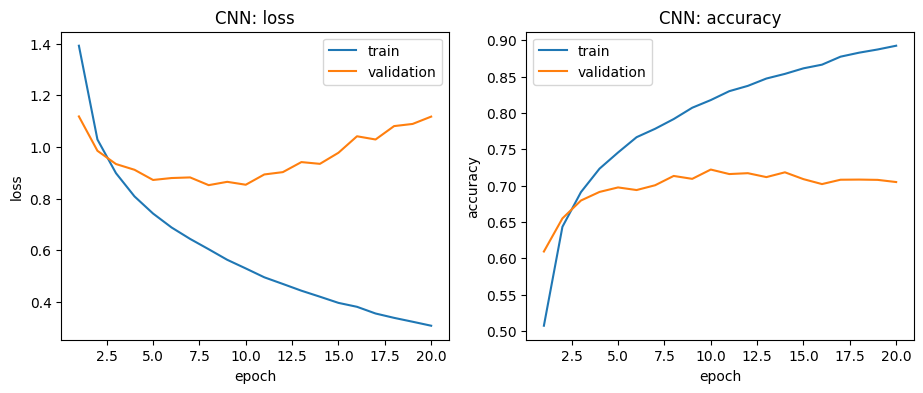

In [11]:
h_cnn = fit(cnn, train_loader, val_loader, epochs=20)
plot_history(h_cnn, "CNN")

CNN training and validation loss (left) and accuracy (right) over 20 epochs.


In [12]:
crit = nn.CrossEntropyLoss()
r_cnn = {"params": count_params(cnn), "history": h_cnn}
for split, ld in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    r_cnn[split + "_loss"], r_cnn[split + "_acc"] = run_epoch(cnn, ld, crit)

for name, r in [("MLP", r_mlp), ("CNN", r_cnn)]:
    print(f"{name}: params {r['params']:,} | "
          f"acc train {r['train_acc']:.3f} val {r['val_acc']:.3f} test {r['test_acc']:.3f} | "
          f"loss train {r['train_loss']:.3f} val {r['val_loss']:.3f} test {r['test_loss']:.3f}")

MLP: params 1,707,274 | acc train 0.891 val 0.520 test 0.528 | loss train 0.309 val 2.547 test 2.531
CNN: params 60,362 | acc train 0.923 val 0.705 test 0.699 | loss train 0.239 val 1.117 test 1.140


## 5. Results

| Metric | MLP | CNN |
|---|---|---|
| Trainable parameters | 1,707,274 | 60,362 |
| Training accuracy | 89.1% | 92.1% |
| Validation accuracy | 52.0% | 70.5% |
| Test accuracy | 52.8% | 69.9% |
| Training loss | 0.309 | 0.243 |
| Validation loss | 2.547 | 1.123 |
| Test loss | 2.531 | 1.135 |
| Generalisation gap (train - test accuracy) | 36.3 points | 22.2 points |

Training metrics in the table were measured after training in evaluation mode. The curves in the figures show values averaged during each epoch, so the final epoch can differ slightly from the table.



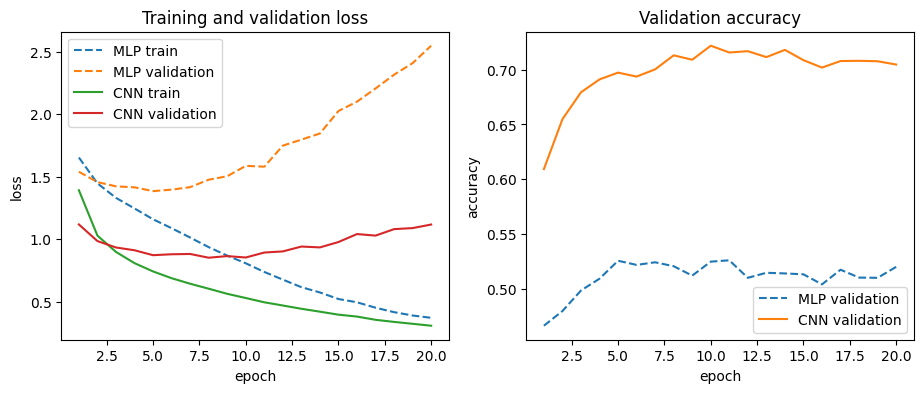

In [13]:
ep = range(1, 21)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for n, h, ls in [("MLP", h_mlp, "--"), ("CNN", h_cnn, "-")]:
    ax[0].plot(ep, h["train_loss"], ls, label=f"{n} train")
    ax[0].plot(ep, h["val_loss"], ls, label=f"{n} validation")
    ax[1].plot(ep, h["val_acc"], ls, label=f"{n} validation")
ax[0].set(title="Training and validation loss", xlabel="epoch", ylabel="loss"); ax[0].legend()
ax[1].set(title="Validation accuracy", xlabel="epoch", ylabel="accuracy"); ax[1].legend()
plt.show()

MLP and CNN training and validation loss (left) and validation accuracy (right).*

## 5. Results

| Metric | MLP | CNN |
|---|---|---|
| Trainable parameters | 1,707,274 | 60,362 |
| Training accuracy | 89.1% | 92.7% |
| Validation accuracy | 52.0% | 70.3% |
| Test accuracy | 52.8% | 70.2% |
| Training loss | 0.309 | 0.233 |
| Validation loss | 2.547 | 1.137 |
| Test loss | 2.531 | 1.155 |
| Generalisation gap (train - test accuracy) | 36.3 points | 22.5 points |

Training metrics in the table were measured after training in evaluation mode. The curves in the figures show values averaged during each epoch, so the final epoch can differ slightly from the table.



In [16]:
best = min(range(20), key=lambda i: h_cnn["val_loss"][i])
print("CNN best val loss:", round(h_cnn["val_loss"][best], 3), "at epoch", best + 1)
print("CNN final val loss:", round(h_cnn["val_loss"][-1], 3))

CNN best val loss: 0.852 at epoch 8
CNN final val loss: 1.117


## 6. Discussion

The CNN outperforms the MLP significantly with 70.2% test accuracy, which is 17.4 percentage points higher than the MLP's 52.8% test accuracy, and with parameters about 28 times lower (60,362 versus 1,707,274). It's also performed better than the MLP (validation loss: 2.547), as its predictions were more accurate and less off target when wrong by less than half.

The answer is in how the two architectures are used for images. The MLP is completely flattening each image and requires a lot of weights (about 92% of them in its first layer) to learn the patterns at each position separately without considering their neighbours. The 2D structure is retained in the CNN. These are all re-used for the entire image (including weight sharing), are sensitive to local features like edges and textures, and provide some tolerance to small translations (max-pooling). The second convolutional layer brings together these features to create more complex features. This provides a more favorable inductive bias for images that have a lot fewer parameters.

Both models suffer from overfitting; degree of overfitting differs. The generalisation gap (training accuracy minus test accuracy) of the MLP increased by 36.3 points and the validation loss continued to climb after it hit its lowest point at epoch 5. The CNN's validation loss was also lower at 22.5 points, but it wasn't spared either as its validation loss hit a minimum of 0.854 at epoch 8 and rose to 1.137 as training loss continued to drop. You can see that its accuracy has stayed at around 70-72% from about epoch 8, but the validation loss has increased, meaning that it is becoming increasingly confident about the wrong predictions and not less accurate. This overfitting was much more subdued than the MLP's (validation loss increased from 0.854 to 1.137, whereas it was around 1.4 to 2.55). This indicates that CNN can be further improved with regularisation (Exercise 3).

The results are obtained from a single run with a fixed seed, and should not be over interpreted as it may give small variations. This is a large accuracy difference however given the variation that we would normally see between runs.